In [1]:
import os

from dotenv import load_dotenv
import librosa
import torch
from pyannote.audio import Pipeline

from IPython.display import Audio, display
from diarization_viewer import show_diarization


/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/pyannote/audio/core/io.py:47: UserWarning: 
torchcodec is not installed correctly so built-in audio decoding will fail. Solutions are:
* use audio preloaded in-memory as a {'waveform': (channel, time) torch.Tensor, 'sample_rate': int} dictionary;
* fix torchcodec installation. Error message was:

Could not load libtorchcodec. Likely causes:
          1. FFmpeg is not properly installed in your environment. We support
             versions 4, 5, 6, 7, and 8, and we attempt to load libtorchcodec
             for each of those versions. Errors for versions not installed on
             your system are expected; only the error for your ins

# 1. Изучите документацию выбранной модели диаризации: как она устроена, что делает
каждый этап пайплайна, какие параметры принимает

выбрана модель pyannote/speaker-diarization-community-1


**Вход** - аудиофайл или тензор звуковых отсчётов. Модель приводит звук к одному каналу и 16 кГц.

 **Выход** - интервалы с метками говорящих, например `0,4–2,8 с → SPEAKER_00`. [Дока](https://huggingface.co/pyannote/speaker-diarization-community-1)




Внутри пайплайна три основных этапа:

1. **Сегментация.** Пайплайн анализирует запись короткими окнами и определяет, в какие моменты внутри каждого окна активны голоса. Он может отметить и одновременную речь.
2. **Извлечение признаков голоса.** Для каждого обнаруженного голоса внутри окна модель строит эмбеддинг по которому можно сравнивать голоса из разных частей записи.
3. **Кластеризация.** Алгоритм VBx группирует эмбеддинги по предполагаемым говорящим. Поэтому один человек, который говорил в начале и снова заговорил через минуту, может получить одну и ту же метку `SPEAKER_00`. Пайплайн переносит эти метки обратно на временные интервалы. [Реализация пайплайна](https://github.com/pyannote/pyannote-audio/blob/main/src/pyannote/audio/pipelines/speaker_diarization.py)



Из параметров вызова для лабы важны `num_speakers` для точного числа говорящих и `min_speakers`, `max_speakers` для нижней и верхней границ. Если их опустить, пайплайн оценивает число говорящих сам.

# 2. Получить доступ к модели

In [2]:
load_dotenv(".env")

pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization-community-1",
    token=os.environ["HF_TOKEN"],
)

print("Модель загружена")

Модель загружена


# 3.  Подготовьте аудио в ожидаемом моделью формате (например, тензор (channels, time) и частота дискретизации) и выполните диаризацию. Модели диаризации тяжёлые: на CPU ограничьтесь короткой записью (1–2 минуты).

In [3]:

duration = 52 # продолжительность в секундах
samples, sample_rate = librosa.load("data.wav", sr=16_000, mono=True, duration=duration)

waveform = torch.from_numpy(samples) # создаёт из массива NumPy тензор PyTorch
waveform = waveform.unsqueeze(0) # добавляет ось в начало. Форма меняется с (960000,) на (1, 960000). Первая ось - каналы, вторая - отсчёты во времени. 1 означает, что запись монофоническая


In [4]:

audio = {"waveform": waveform, "sample_rate": sample_rate}
output = pipeline(audio)

for turn, speaker in output.speaker_diarization:
    print(f"{turn.start:.2f}–{turn.end:.2f} с  {speaker}")




/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/pyannote/audio/models/blocks/pooling.py:103: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  std = sequences.std(dim=-1, correction=1)


4.30–7.46 с  SPEAKER_02
7.69–8.47 с  SPEAKER_02
8.47–8.64 с  SPEAKER_00
8.64–10.43 с  SPEAKER_02
13.97–14.04 с  SPEAKER_02
14.97–15.00 с  SPEAKER_02
24.74–27.27 с  SPEAKER_00
27.42–27.71 с  SPEAKER_00
27.71–27.74 с  SPEAKER_01
27.99–28.11 с  SPEAKER_01
30.24–32.50 с  SPEAKER_01
33.38–34.71 с  SPEAKER_01
35.69–36.97 с  SPEAKER_00
37.80–38.61 с  SPEAKER_01
38.78–41.00 с  SPEAKER_01
42.64–43.16 с  SPEAKER_01
45.39–46.27 с  SPEAKER_01
46.64–47.94 с  SPEAKER_01
48.23–49.19 с  SPEAKER_01
50.98–51.70 с  SPEAKER_01


/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



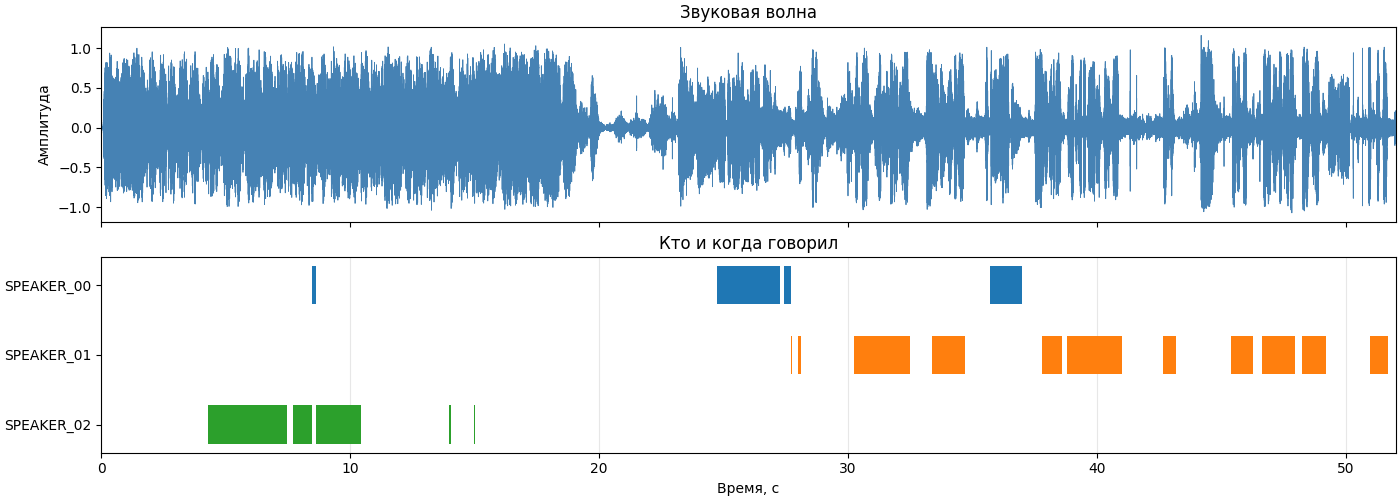

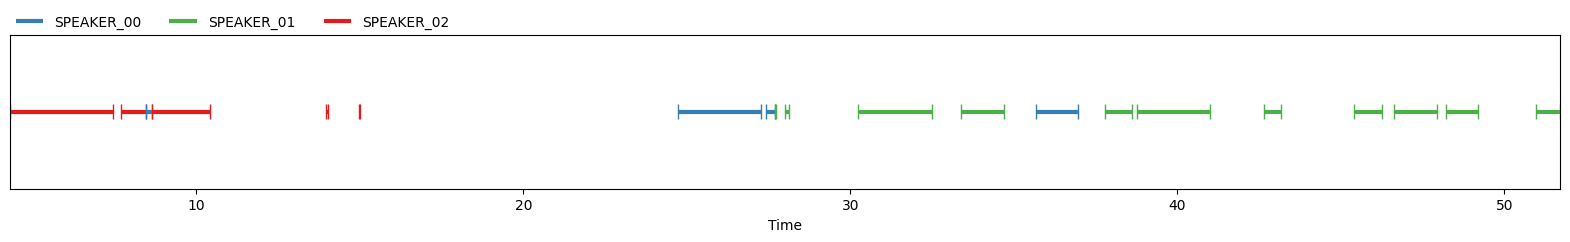

In [5]:
show_diarization(samples, sample_rate, output.speaker_diarization)


In [6]:
del pipeline

# 4. Разберитесь с параметрами, управляющими результатом: ограничение числа спикеров ( min_speakers , max_speakers ) и другие настройки — объясните их влияние на результат

/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/pyannote/audio/models/blocks/pooling.py:103: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  std = sequences.std(dim=-1, correction=1)


4.30–7.46 с  SPEAKER_02
7.69–10.43 с  SPEAKER_02
13.97–14.04 с  SPEAKER_02
14.97–15.00 с  SPEAKER_02
24.74–27.27 с  SPEAKER_00
27.42–27.72 с  SPEAKER_00
27.72–27.74 с  SPEAKER_03
27.99–28.11 с  SPEAKER_03
30.24–32.50 с  SPEAKER_03
33.38–34.71 с  SPEAKER_03
35.69–36.97 с  SPEAKER_00
37.80–38.61 с  SPEAKER_01
38.78–41.00 с  SPEAKER_01
42.64–43.16 с  SPEAKER_01
45.39–46.27 с  SPEAKER_01
46.64–47.94 с  SPEAKER_01
48.23–49.19 с  SPEAKER_01
50.98–51.70 с  SPEAKER_01


/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



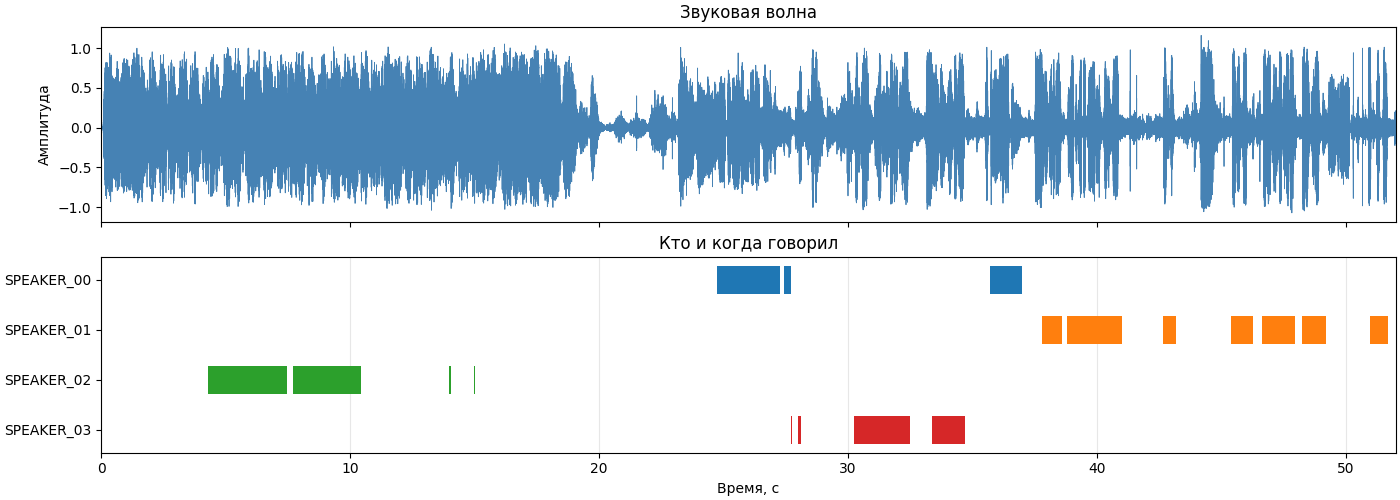

In [8]:
pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization-community-1",
    token=os.environ["HF_TOKEN"],
)

output = pipeline(audio, num_speakers=4)

for turn, speaker in output.speaker_diarization:
    print(f"{turn.start:.2f}–{turn.end:.2f} с  {speaker}")
output = show_diarization(samples, sample_rate, output.speaker_diarization)

In [9]:
del pipeline

segmentation.min_duration_off - задаёт, какие короткие паузы между соседними сегментами одного спикера заполнять в итоговой разметке. Например, при 0.3 секунды два отрезка одного спикера с паузой 0.2 секунды между ними могут стать одной полосой

/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/pyannote/audio/models/blocks/pooling.py:103: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1858.)
  std = sequences.std(dim=-1, correction=1)


4.30–10.43 с  SPEAKER_02
13.97–14.04 с  SPEAKER_02
14.97–15.00 с  SPEAKER_02
24.74–27.72 с  SPEAKER_00
27.72–28.11 с  SPEAKER_03
30.24–32.50 с  SPEAKER_03
33.38–34.71 с  SPEAKER_03
35.69–36.97 с  SPEAKER_00
37.80–41.00 с  SPEAKER_01
42.64–43.16 с  SPEAKER_01
45.39–46.27 с  SPEAKER_01
46.64–49.19 с  SPEAKER_01
50.98–51.70 с  SPEAKER_01


/home/topi768/FEFU7_remote/Нейронные сети/venv/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



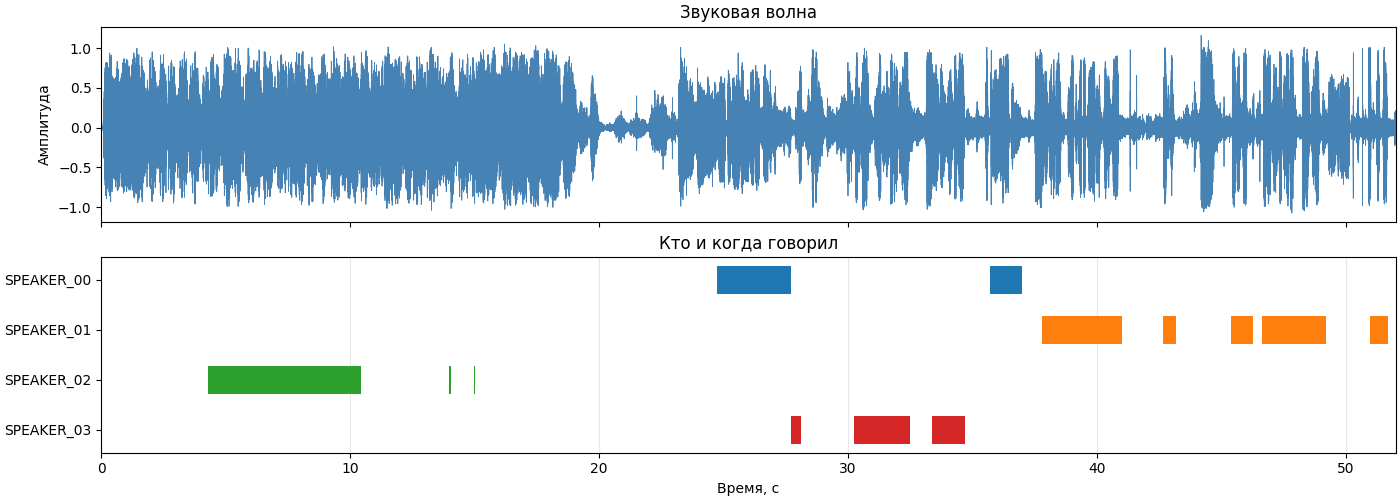

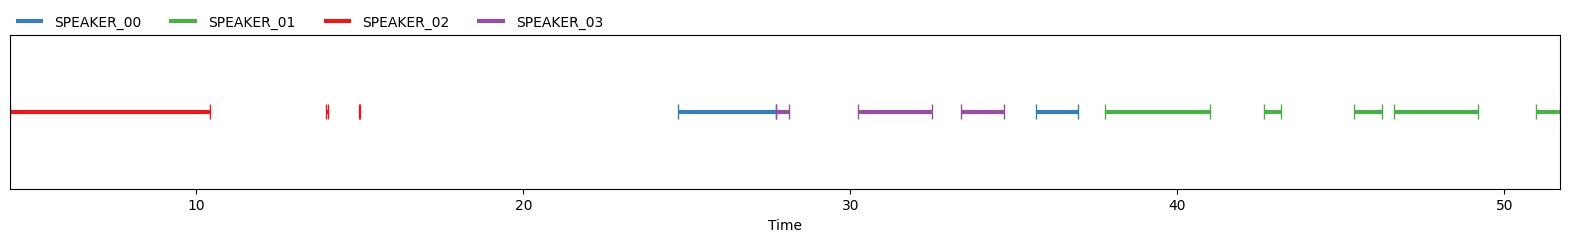

In [10]:
pipeline = Pipeline.from_pretrained(
    "pyannote/speaker-diarization-community-1",
    token=os.environ["HF_TOKEN"],
)

pipeline.instantiate({"segmentation": {"min_duration_off": 0.3}})

output = pipeline(audio, num_speakers=4)

for turn, speaker in output.speaker_diarization:
    print(f"{turn.start:.2f}–{turn.end:.2f} с  {speaker}")

show_diarization(samples, sample_rate, output.speaker_diarization)

красную зону снизу он обединил. До этого было 2 тонких полоски. По умолчанию min_duration_off = 0

del pipeline

# 5. Получите транскрипцию записи (например, моделью из работы 2) и сопоставьте её с сегментами диаризации: по пересечению временных интервалов отнесите каждый сегмент текста к своему спикеру (условие перекрытия: max(segment.start, turn.start) < min(segment.end, turn.end) ).


In [12]:
import whisper

model = whisper.load_model("small", device="cuda")
result = model.transcribe(samples, language=None, fp16=False)

print("Язык:", result["language"])

turns = list(output.speaker_diarization)
matched_segments = []

for segment in result["segments"]:
    start = segment["start"]
    end = segment["end"]
    text = segment["text"].strip()

    overlap_by_speaker = {}

    for turn, speaker in turns:
        overlap_start = max(start, turn.start)
        overlap_end = min(end, turn.end)

        if overlap_start < overlap_end:
            overlap = overlap_end - overlap_start
            overlap_by_speaker[speaker] = overlap_by_speaker.get(speaker, 0) + overlap

    speaker = max(
        overlap_by_speaker,
        key=overlap_by_speaker.get,
        default="Не определён",
    )

    matched_segments.append({
        "start": start,
        "end": end,
        "speaker": speaker,
        "text": text,
    })

    print(f"{start:.2f}–{end:.2f} с  {speaker}  {text}")
display(Audio(samples, rate=sample_rate))


Язык: ru
0.00–11.00 с  SPEAKER_02  Па-ра-м-тай, рапу-ди-ра-м-тай
11.00–20.00 с  SPEAKER_02  Па-ра-м-тай, рапу-ди-ра-м-тай
24.00–27.00 с  SPEAKER_00  Может, пойдем лучше накачать или покачаемся?
30.00–33.00 с  SPEAKER_03  Успеем! Смотри, сколько тут всего!
33.00–35.00 с  SPEAKER_03  Интересного!
35.00–37.00 с  SPEAKER_00  Что это такое?
37.00–41.00 с  SPEAKER_01  Это телеграф средства общений на расстоянии.
42.00–43.00 с  SPEAKER_01  Как это?
45.00–49.00 с  SPEAKER_01  Очень просто! Печаточный сообщений и отсылающий.
50.00–52.00 с  SPEAKER_01  А где тут?


# 6. Группировка текста по спикерам

In [ ]:
texts_by_speaker = {}

for segment in matched_segments:
    speaker = segment["speaker"]
    texts_by_speaker.setdefault(speaker, []).append(segment["text"])

for speaker, texts in texts_by_speaker.items():
    print(f"\n{speaker}")
    for text in texts:
        print(f"  {text}")


SPEAKER_02
  Па-ра-м-тай, рапу-ди-ра-м-тай
  Па-ра-м-тай, рапу-ди-ра-м-тай

SPEAKER_00
  Может, пойдем лучше накачать или покачаемся?
  Что это такое?

SPEAKER_03
  Успеем! Смотри, сколько тут всего!
  Интересного!

SPEAKER_01
  Это телеграф средства общений на расстоянии.
  Как это?
  Очень просто! Печаточный сообщений и отсылающий.
  А где тут?
